In [34]:
import importlib
import os
import sys
from collections import namedtuple

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from scipy.ndimage import gaussian_filter

sys.path.append(os.path.abspath('..'))
from scripts import analysis_utils as au
importlib.reload(au)

plt.rcParams.update({'font.size': 14})
plt.rcParams['axes.grid'] = False
mpl.rcParams['font.family'] = 'monospace'

In [35]:
data_tsamp40_ndays1 = np.load('transmissivity_prediction_tsamp4.096e-05_ndays1_nchan4096.npy')
data_tsamp40_ndays7 = np.load('transmissivity_prediction_tsamp4.096e-05_ndays7_nchan4096.npy')
data_tsamp40_ndays30 = np.load('transmissivity_prediction_tsamp4.096e-05_ndays30_nchan4096.npy')

data_tsamp64_ndays1 = np.load('transmissivity_prediction_tsamp6.4e-05_ndays1_nchan4096.npy')
data_tsamp64_ndays7 = np.load('transmissivity_prediction_tsamp6.4e-05_ndays7_nchan4096.npy')
data_tsamp64_ndays30 = np.load('transmissivity_prediction_tsamp6.4e-05_ndays30_nchan4096.npy')

data_tsamp128_ndays1 = np.load('transmissivity_prediction_tsamp0.000128_ndays1_nchan4096.npy')
data_tsamp128_ndays7 = np.load('transmissivity_prediction_tsamp0.000128_ndays7_nchan4096.npy')
data_tsamp128_ndays30 = np.load('transmissivity_prediction_tsamp0.000128_ndays30_nchan4096.npy')

data_tsamp983_ndays1 = np.load('transmissivity_prediction_tsamp0.00098304_ndays1_nchan4096.npy')
data_tsamp983_ndays7 = np.load('transmissivity_prediction_tsamp0.00098304_ndays7_nchan4096.npy')
data_tsamp983_ndays30 = np.load('transmissivity_prediction_tsamp0.00098304_ndays30_nchan4096.npy')

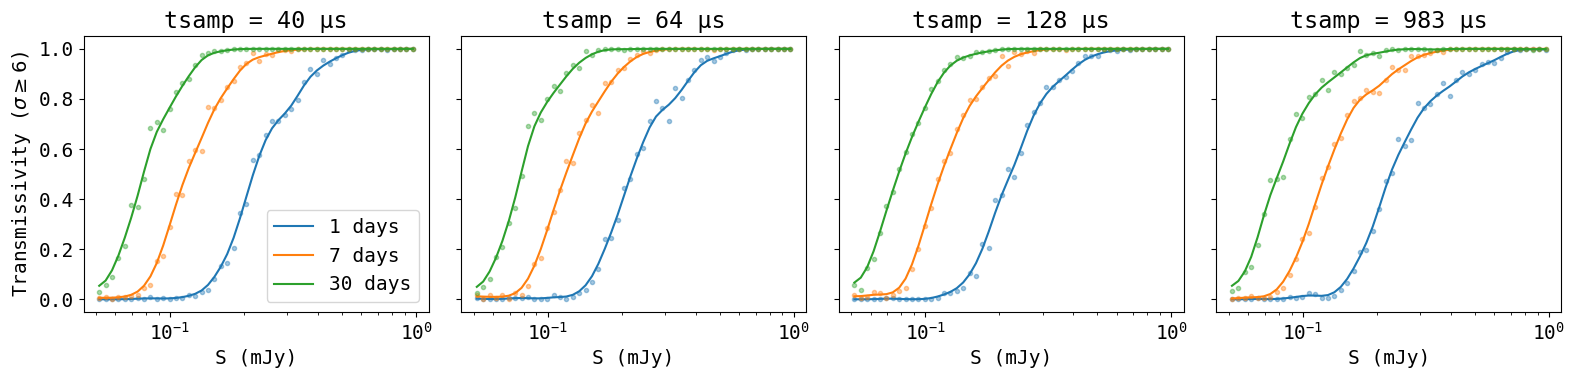

In [36]:
datasets = {
    (40, 1): data_tsamp40_ndays1,   (40, 7): data_tsamp40_ndays7,   (40, 30): data_tsamp40_ndays30,
    (64, 1): data_tsamp64_ndays1,   (64, 7): data_tsamp64_ndays7,   (64, 30): data_tsamp64_ndays30,
    (128, 1): data_tsamp128_ndays1, (128, 7): data_tsamp128_ndays7, (128, 30): data_tsamp128_ndays30,
    (983, 1): data_tsamp983_ndays1, (983, 7): data_tsamp983_ndays7, (983, 30): data_tsamp983_ndays30,
}

# common log-spaced flux bins across all datasets
s_min = min(d["flux"].min() for d in datasets.values())
s_max = max(d["flux"].max() for d in datasets.values())
flux_bins = np.logspace(np.log10(s_min), np.log10(s_max), 51)
flux_centers = np.sqrt(flux_bins[:-1] * flux_bins[1:])
gauss_dev = 1.5   # smoothing width, in bins

curves = {}
for key, data in datasets.items():
    inj_per_beam, p_found, p_found_smooth = au.get_sensitivity(
        data, "flux", flux_bins, gauss_dev,
        stype="1d", predicted=True,
        sigma_col="predicted_sigma", sigma_threshold=6.,
    )
    curves[key] = (p_found, p_found_smooth, inj_per_beam)
# curves[(tsamp_us, ndays)] -> (raw, smoothed, injections per beam), each shape (len(flux_centers),)

# plot
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, ts in zip(axes, (40, 64, 128, 983)):
    for nd in (1, 7, 30):
        p, p_smooth, _ = curves[(ts, nd)]
        line, = ax.plot(flux_centers, p_smooth, label=f"{nd} days")
        ax.plot(flux_centers, p, ".", color=line.get_color(), alpha=0.4)
    ax.set_xscale("log")
    ax.set_title(f"tsamp = {ts} µs")
    ax.set_xlabel("S (mJy)")
axes[0].set_ylabel(r"Transmissivity ($\sigma \geq 6$)")
axes[0].legend()
plt.tight_layout()

/data1/people/rsquillace/Transmissivity/scripts/analysis_utils.py:63: RuntimeWarning: invalid value encountered in divide
  # mask thin


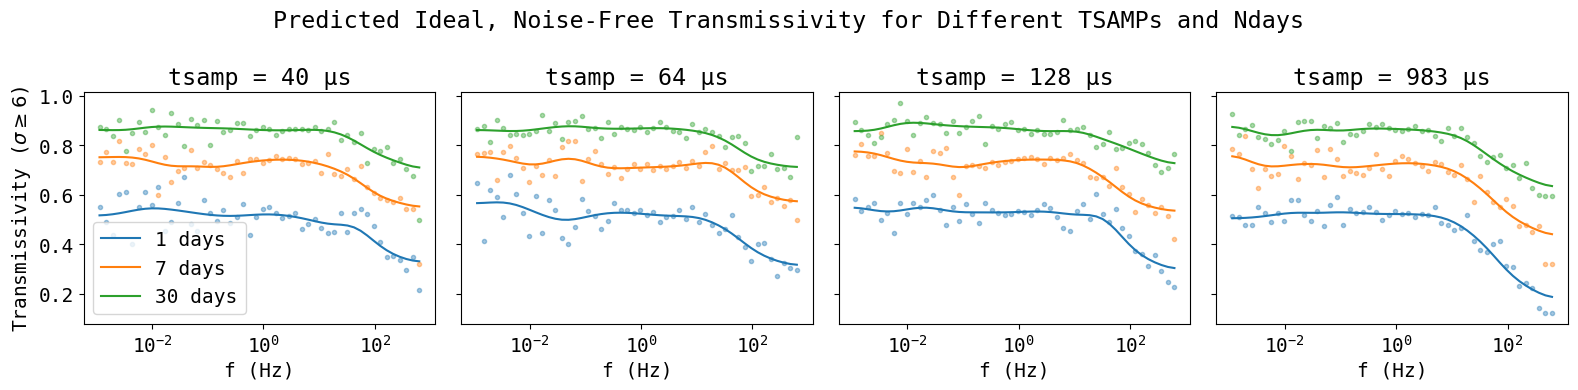

In [37]:
f_min = min(d["frequency"].min() for d in datasets.values())
f_max = max(d["frequency"].max() for d in datasets.values())
freq_bins = np.logspace(np.log10(f_min), np.log10(f_max), 51)
freq_centers = np.sqrt(freq_bins[:-1] * freq_bins[1:])
gauss_dev = 3

curves = {}
for key, data in datasets.items():
    inj_per_beam, p_found, p_found_smooth = au.get_sensitivity(
        data, "frequency", freq_bins, gauss_dev,
        stype="1d", predicted=True,
        sigma_col="predicted_sigma", sigma_threshold=6.,
    )
    curves[key] = (p_found, p_found_smooth, inj_per_beam)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, ts in zip(axes, (40, 64, 128, 983)):
    for nd in (1, 7, 30):
        p, p_smooth, _ = curves[(ts, nd)]
        line, = ax.plot(freq_centers, p_smooth, label=f"{nd} days")
        ax.plot(freq_centers, p, ".", color=line.get_color(), alpha=0.4)
    ax.set_xscale("log")
    ax.set_title(f"tsamp = {ts} µs")
    ax.set_xlabel("f (Hz)")
axes[0].set_ylabel(r"Transmissivity ($\sigma \geq 6$)")
axes[0].legend()
fig.suptitle('Predicted Ideal, Noise-Free Transmissivity for Different TSAMPs and Ndays')
plt.tight_layout()

Text(0.5, 0.98, 'Predicted Ideal, Noise-Free Transmissivity for Different TSAMPs and Ndays')

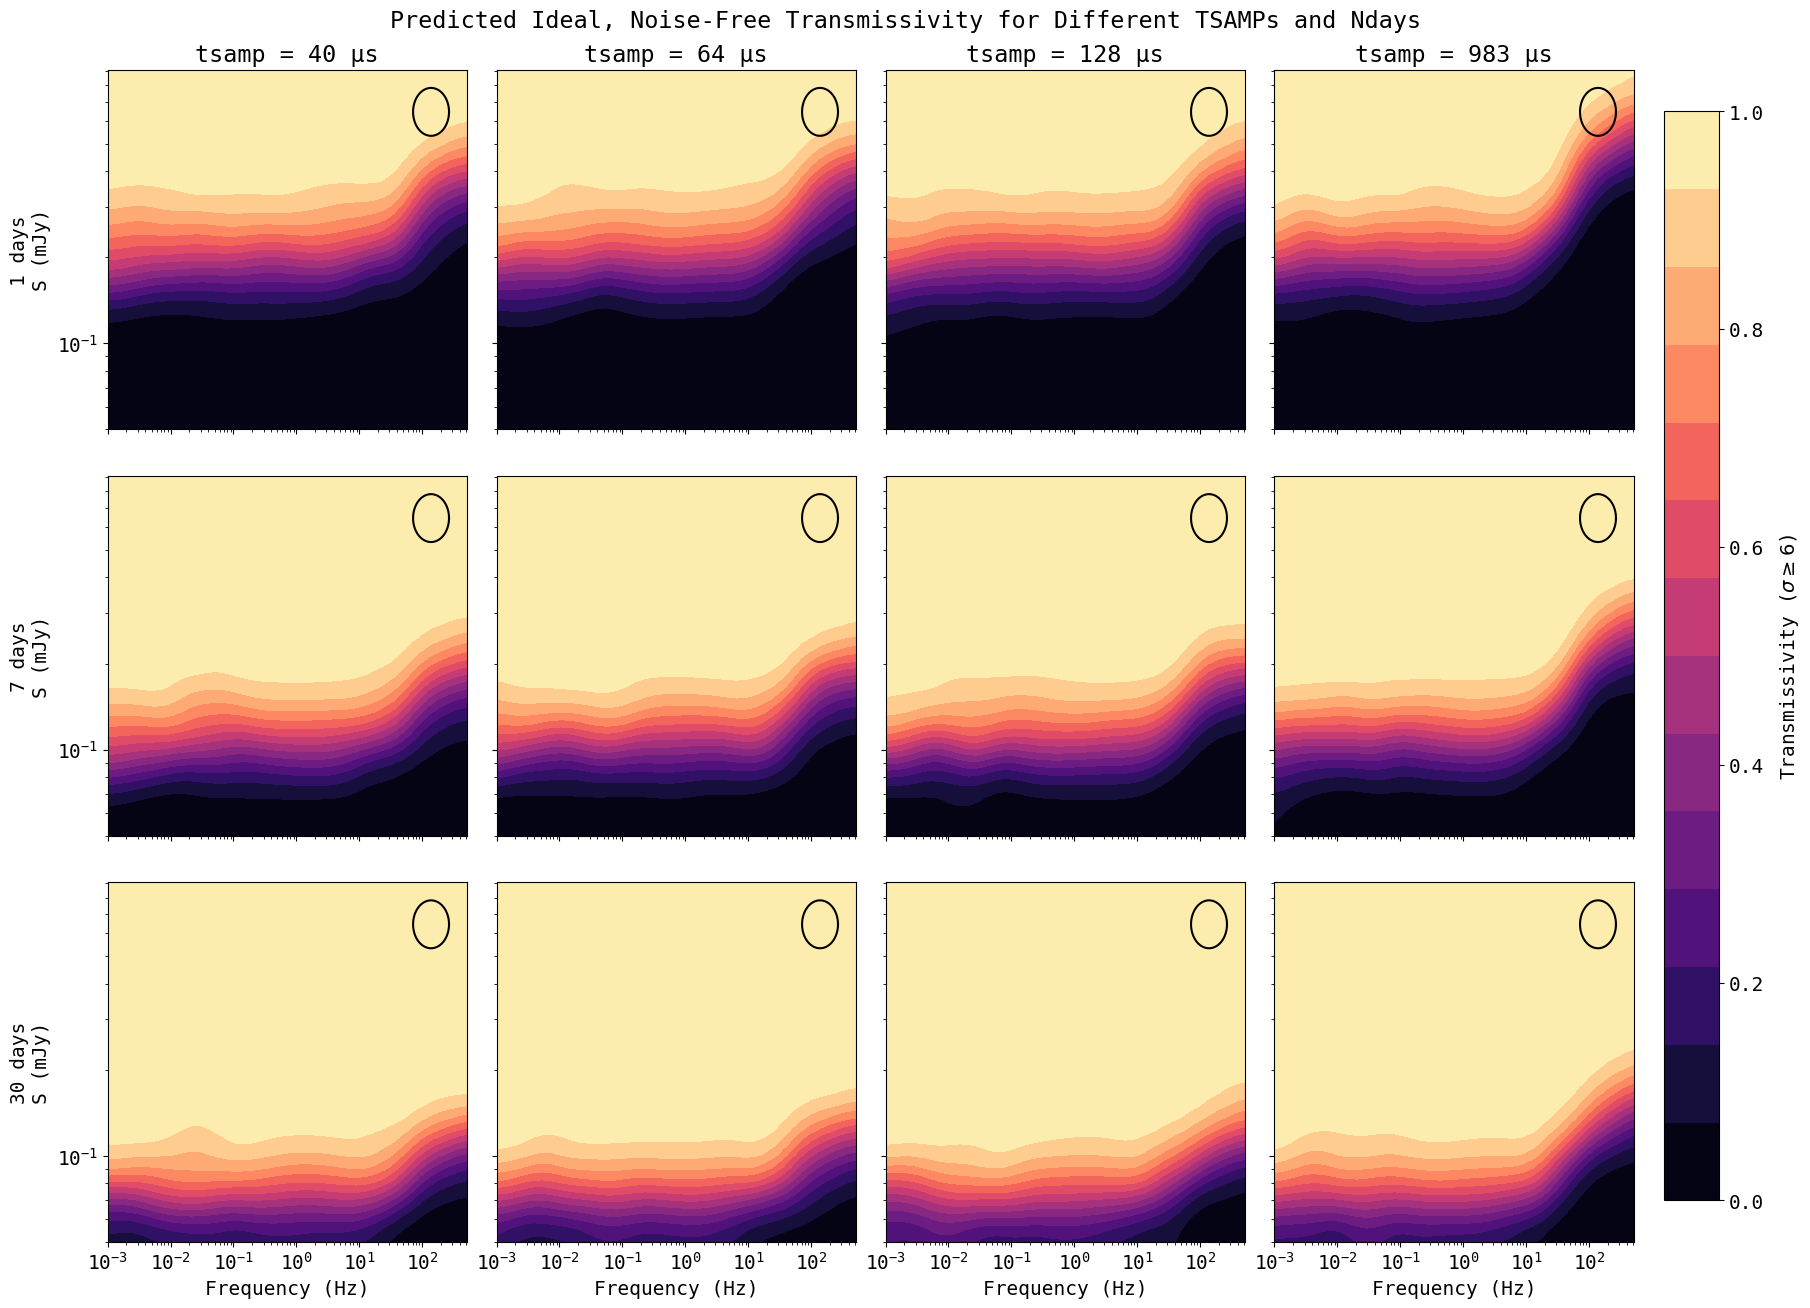

In [40]:
f_min = min(d["frequency"].min() for d in datasets.values())
f_max = max(d["frequency"].max() for d in datasets.values())
s_min = min(d["flux"].min() for d in datasets.values())
s_max = max(d["flux"].max() for d in datasets.values())
freq_bins = np.logspace(np.log10(f_min), np.log10(f_max), 41)
flux_bins = np.logspace(np.log10(s_min), np.log10(s_max), 31)
dev_f, dev_s = 2, 2

maps = {}
for key, data in datasets.items():
    inj_per_beam, p_found, p_found_smooth = au.get_sensitivity(
        data, "flux", "frequency", flux_bins, freq_bins, dev_s, dev_f,
        stype="2d", predicted=True,
        sigma_col="predicted_sigma", sigma_threshold=6.,
    )
    maps[key] = (p_found, p_found_smooth, inj_per_beam)

tsamps, ndays_list = (40, 64, 128, 983), (1, 7, 30)
fig, axes = plt.subplots(len(ndays_list), len(tsamps), figsize=(18, 13),
                         sharex=True, sharey=True, layout="constrained")
for row, nd in enumerate(ndays_list):
    for col, ts in enumerate(tsamps):
        _, p_smooth, _ = maps[(ts, nd)]
 
        ellipse_color = "k" if np.nanmean(p_smooth[-4:, -4:]) > 0.5 else "w"
        cf = au.populate_contour_map(
            axes[row, col], p_smooth,
            freq_bins, flux_bins,   
            dev_f, dev_s,
            title=f"tsamp = {ts} µs" if row == 0 else None,
            xlabel="Frequency (Hz)" if row == len(ndays_list) - 1 else None,
            ylabel=f"{nd} days\nS (mJy)" if col == 0 else None,
            xlog=True, ylog=True,
            ellipse_color=ellipse_color,
        )

cbar = fig.colorbar(cf, ax=axes, location="right", pad=0.02, shrink=0.9)
cbar.set_label(r"Transmissivity ($\sigma \geq 6$)", labelpad=10)
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
fig.suptitle("Predicted Ideal, Noise-Free Transmissivity for Different TSAMPs and Ndays")